In [12]:
import json

import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat

from modules import apodization

In [13]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [14]:
params = load_parameters('/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/master_thesis/001_params_angles.json')

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling


Effective array length:  0.005000197722239797 first_transducer:  20 transducers_in_effective_array:  51


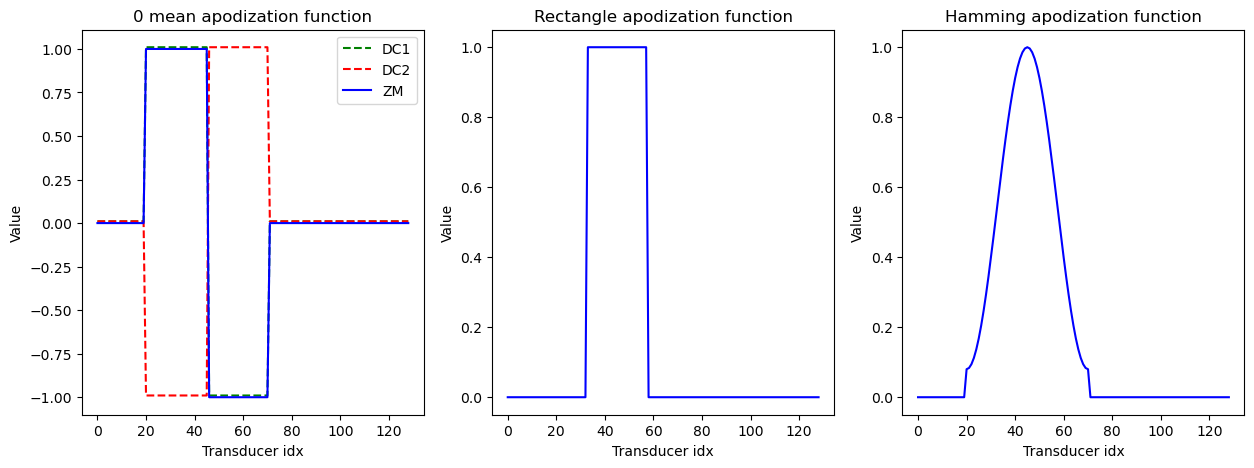

In [15]:
effective_array_length, transducers_in_effective_array, first_transducer = apodization.find_object_effective_aperture(200*2.25e-5, 1331*0.0095/3161, params["array"]["aperture"], params["array"]['length'], params["array"]["pitch"])
print("Effective array length: ", effective_array_length, "first_transducer: ", first_transducer, "transducers_in_effective_array: ", transducers_in_effective_array)

apodization_zm = apodization.apodization_wrapper("zm", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"], 0.01)
apodization_dc1 = apodization.apodization_wrapper("dc1", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"], 0.01)
apodization_dc2 = apodization.apodization_wrapper("dc2", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"], 0.01)
apodization_rectangle = apodization.apodization_wrapper("rectangle", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"], 0.01)
apodization_hamming = apodization.apodization_wrapper("hamming", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 1, params["array"]["pitch"], 0.01)

fig, ax = plt.subplots(1,3, figsize=(15, 5))

ax[0].plot(pos, apodization_dc1, color='g', ls='--', label='DC1')
ax[0].plot(pos, apodization_dc2, color='r', ls='--', label ='DC2')
ax[0].plot(pos, apodization_zm, color='b', label='ZM')

ax[0].set_title('0 mean apodization function')
ax[0].set_xlabel('Transducer idx')
ax[0].set_ylabel('Value')
ax[0].legend()

ax[1].plot(pos, apodization_rectangle, color='b')
ax[1].set_title('Rectangle apodization function')
ax[1].set_xlabel('Transducer idx')
ax[1].set_ylabel('Value')

ax[2].plot(pos, apodization_hamming, color='b')
ax[2].set_title('Hamming apodization function')
ax[2].set_xlabel('Transducer idx')
ax[2].set_ylabel('Value')

plt.show()

# Visulize RF daata

In [16]:
rf_path_original =  "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/rf0001.mat"
rf_matrix_original = loadmat(rf_path_original)
rf_matrix_original = list(rf_matrix_original.values())[-1]
rf_matrix_original = np.float32(rf_matrix_original)

In [17]:
print("RF matrix shape: ", rf_matrix_original.shape)

RF matrix shape:  (768, 128, 16, 160)


In [18]:
rf_path =  "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/concat/IQ/640_concat_IQ_rf.npy"
rf_matrix = np.lib.format.open_memmap(rf_path, mode='r', dtype=np.complex64)
print("RF matrix shape: ", rf_matrix.shape)

RF matrix shape:  (1535, 128, 16, 640)


In [19]:
rf_matrix_viz = rf_matrix[:, :, 0, 0]
rf_matrix_original = rf_matrix_original[:, :, 0,0]

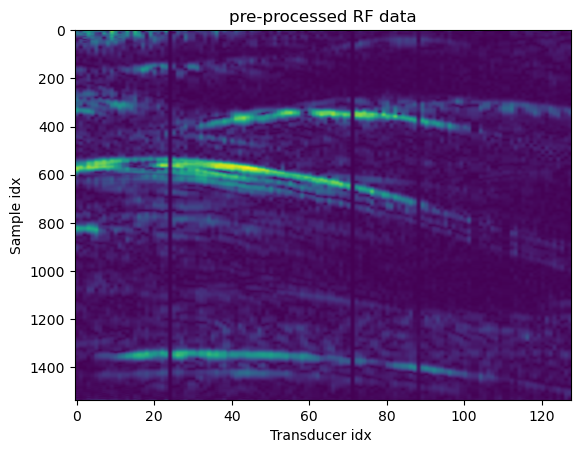

In [20]:
plt.imshow(np.abs(rf_matrix_viz), aspect='auto', cmap='viridis')
plt.title("pre-processed RF data")
plt.xlabel("Transducer idx ")
plt.ylabel("Sample idx")
plt.show()

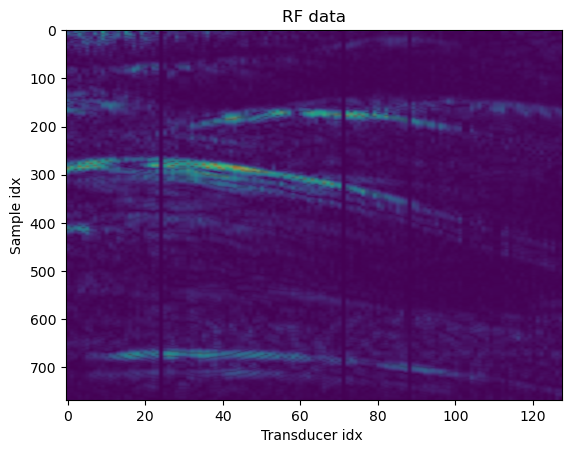

In [21]:
plt.imshow(np.abs(rf_matrix_original), aspect='auto', cmap='viridis')
plt.title("RF data")
plt.xlabel("Transducer idx ")
plt.ylabel("Sample idx")
plt.show()